# Funktionen mehrerer Veränderlicher IV: Die Richtungsableitung

**Begleit-Notebook zum Vorlesungsskript „Angewandte Mathematik – 2. Funktionen mehrerer Veränderlicher“ (Abschnitt 2.5)**

Das Notebook folgt der Gliederung des Skripts. Definitionen, Sätze und Beispiele tragen dieselbe Nummer wie im Skript. Zu den Beispielen gibt es

* den Rechenweg aus dem Skript in Formeln,
* eine **Probe mit SymPy** (das Residuum muss 0 sein),
* eine **Grafik** und an einigen Stellen ein **interaktives Element** (Schieberegler),

**Voraussetzungen:** `numpy`, `sympy`, `matplotlib`, `ipywidgets`
**Arbeitsweise:** Zellen der Reihe nach ausführen und die Kontrollausgaben prüfen.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/funktionen_mehrerer_veraenderlicher/04_richtungsableitung.ipynb)

**Inhalt**


1. Definition 2.5.1: Richtungsableitung als Grenzwert
2. Satz 2.5.2: $\frac{\partial f}{\partial a}(x_0) = a\cdot\nabla f(x_0)$ (mit Beweisidee und Gegenbeispiel ohne $C^1$)
3. Satz 2.5.3: maximale und minimale Steigung
4. Beispiel 2.5.4: $f(x,y) = e^{-x}\sin y$
5. Beispiel 2.5.5: Richtungsableitung in Abhängigkeit vom Winkel
6. Anwendung: Gradientenabstieg


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
from matplotlib import cm
plt.style.use('default')
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})
sp.init_printing()

x, y, z = sp.symbols('x y z', real=True)
ROT, BLAU = '#d71920', '#0b5cad'


def pruefe(name, residuum):
    """Vereinfacht ein Residuum, gibt es aus und bricht ab, falls es nicht 0 ist."""
    r = sp.simplify(residuum)
    if isinstance(r, sp.MatrixBase):
        ok = all(sp.simplify(e) == 0 for e in r)
    else:
        ok = r == 0
    print(f'Probe {name}: Residuum = {r}  ->', 'ok' if ok else 'FEHLER')
    assert ok


def flaeche(f, xbereich, ybereich, n=60, ax=None, titel=None, cmap='YlOrBr_r', alpha=1.0, blick=(30, -60)):
    """Zeichnet z = f(x, y) als Fläche (f als NumPy-Funktion). Gibt die Achse zurück."""
    if ax is None:
        fig = plt.figure(figsize=(7, 5))
        ax = fig.add_subplot(projection='3d')
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    ax.plot_surface(X, Y, Z, cmap=cmap, alpha=alpha, linewidth=0.2, edgecolor=(0.3, 0.15, 0, 0.3),
                    rstride=max(1, n // 30), cstride=max(1, n // 30))
    ax.set(xlabel='x', ylabel='y', zlabel='z')
    ax.view_init(*blick)
    if titel:
        ax.set_title(titel)
    return ax


def hoehenlinien(f, xbereich, ybereich, n=300, ax=None, niveaus=12, titel=None, gefuellt=True):
    """Zeichnet die Höhenlinien f(x, y) = c (optional eingefärbt). Gibt die Achse zurück."""
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    if gefuellt:
        cf = ax.contourf(X, Y, Z, levels=niveaus, cmap='YlOrBr_r', extend='both')
        plt.colorbar(cf, ax=ax, shrink=0.85)
    cs = ax.contour(X, Y, Z, levels=niveaus, colors='0.25', linewidths=0.7)
    ax.clabel(cs, fontsize=7, fmt='%.2g')
    ax.set(xlabel='x', ylabel='y', aspect='equal')
    if titel:
        ax.set_title(titel)
    return ax


lam, alpha = sp.symbols('lambda alpha', real=True)

## 1. Definition 2.5.1: Richtungsableitung

Die partiellen Ableitungen messen die Steigung nur in Richtung der Koordinatenachsen. Oft braucht man die Steigung in einer **beliebigen Richtung**.

Es sei $f:D\subseteq\mathbb{R}^m\to\mathbb{R}$, $x_0\in D$ und $a\in\mathbb{R}^m$ mit $\|a\| = 1$. Der Grenzwert
$$\frac{\partial f}{\partial a}(x_0) = \lim_{\lambda\to 0}\frac{f(x_0 + \lambda a) - f(x_0)}{\lambda}$$
heißt **Richtungsableitung** von $f$ in $x_0$ in Richtung $a$. Er gibt die momentane Änderungsrate von $f$ an, wenn man sich von $x_0$ aus in Richtung $a$ bewegt.

* Für $a = e_i$ (Einheitsvektor) erhält man die partielle Ableitung $f_{x_i}$.
* Die Bedingung $\|a\| = 1$ sorgt dafür, dass man „pro Längeneinheit“ misst. Ein längerer Vektor würde die Rate entsprechend vergrößern.

## 2. Satz 2.5.2

Ist $f\in C^1(D)$, $x_0\in D$ und $\|a\| = 1$, so gilt
$$\frac{\partial f}{\partial a}(x_0) = a\cdot\nabla f(x_0).$$

**Beweisidee:** Auf der Geraden $x(\lambda) = x_0 + \lambda a$ ist $h(\lambda) = f(x(\lambda))$ eine Funktion einer Variablen, und die Richtungsableitung ist $h'(0)$. Mit der Kettenregel (Bemerkung 2.4.13) und $x(0) = x_0$, $x'(\lambda) = a$:
$$h'(0) = \sum_{i=1}^m\frac{\partial f}{\partial x_i}(x_0)\,a_i = a\cdot\nabla f(x_0).$$

Die Probe vergleicht für eine allgemeine glatte Funktion die Definition (Grenzwert) mit der Formel.

In [2]:
a1, a2 = sp.symbols('a1 a2', real=True)
f_test = sp.exp(x)*sp.cos(y) + x*y**2
x0, y0 = sp.Rational(1, 2), 1
grenzwert = sp.limit((f_test.subs({x: x0 + lam*a1, y: y0 + lam*a2}) - f_test.subs({x: x0, y: y0}))/lam, lam, 0)
formel = (sp.Matrix([[a1, a2]])*sp.Matrix([f_test]).jacobian([x, y]).T).subs({x: x0, y: y0})[0]
pruefe('Definition 2.5.1 = a · ∇f', grenzwert - formel)

Probe Definition 2.5.1 = a · ∇f: Residuum = 0  -> ok


**Warum $f\in C^1$ nötig ist:** Für
$$f(x,y) = \frac{x^2y}{x^2 + y^2},\qquad f(0,0) = 0,$$
existieren in $(0,0)$ **alle** Richtungsableitungen, und $\nabla f(0,0) = (0,0)$. Trotzdem ist die Richtungsableitung in Richtung $a = (\cos\alpha, \sin\alpha)$ gleich $\cos^2\alpha\sin\alpha$ und nicht $a\cdot\nabla f(0,0) = 0$. Die partiellen Ableitungen sind in $(0,0)$ nicht stetig, $f$ ist dort nicht differenzierbar.

∇f(0,0) = (0, 0)
Richtungsableitung in Richtung (cos α, sin α): sin(alpha)*cos(alpha)**2   (a · ∇f(0,0) wäre 0)


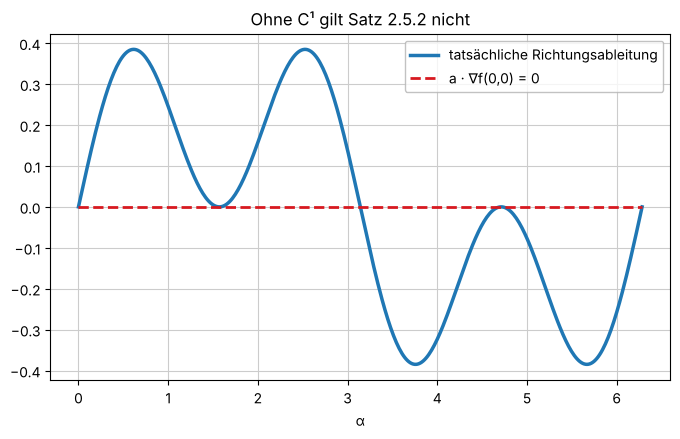

In [3]:
f_ge = x**2*y/(x**2 + y**2)
fx0 = sp.limit((f_ge.subs({x: lam, y: 0}) - 0)/lam, lam, 0)
fy0 = sp.limit((f_ge.subs({x: 0, y: lam}) - 0)/lam, lam, 0)
print('∇f(0,0) =', (fx0, fy0))
richtung = sp.simplify((f_ge.subs({x: lam*sp.cos(alpha), y: lam*sp.sin(alpha)}) - 0)/lam)
print('Richtungsableitung in Richtung (cos α, sin α):', richtung, '  (a · ∇f(0,0) wäre 0)')
als = np.linspace(0, 2*np.pi, 400)
plt.plot(als, np.cos(als)**2*np.sin(als), linewidth=2.5, label='tatsächliche Richtungsableitung')
plt.plot(als, 0*als, '--', color=ROT, linewidth=2, label='a · ∇f(0,0) = 0')
plt.xlabel('α'); plt.title('Ohne C¹ gilt Satz 2.5.2 nicht'); plt.legend(); plt.show()

## 3. Satz 2.5.3 (maximale Steigung)

Ist $f$ in $x\in D$ differenzierbar, so gilt:

(a) Die **größte** Steigung von $f$ in $x$ ist $\|\nabla f(x)\| = \sqrt{f_{x_1}(x)^2 + \dots + f_{x_m}(x)^2}$. Sie wird in Richtung $a = \nabla f(x)/\|\nabla f(x)\|$ angenommen.
(b) Die **kleinste** Steigung ist $-\|\nabla f(x)\|$, in Richtung $-\nabla f(x)$.

**Begründung:** Mit dem Winkel $\theta$ zwischen $a$ und $\nabla f(x)$ ist
$$\frac{\partial f}{\partial a}(x) = a\cdot\nabla f(x) = \|a\|\,\|\nabla f(x)\|\cos\theta = \|\nabla f(x)\|\cos\theta,$$
maximal für $\theta = 0$, minimal für $\theta = \pi$ und $0$ für $\theta = \pi/2$ (Richtung der Höhenlinie).

## 4. Beispiel 2.5.4

Gesucht ist die Richtungsableitung von $f(x,y) = e^{-x}\sin y$ in $\left(0, \frac{\pi}{6}\right)$ in Richtung $a = \left(\frac35, \frac45\right)$.

$$f_x = -e^{-x}\sin y\ \Rightarrow\ f_x\left(0,\tfrac{\pi}{6}\right) = -\tfrac12,\qquad f_y = e^{-x}\cos y\ \Rightarrow\ f_y\left(0,\tfrac{\pi}{6}\right) = \tfrac12\sqrt3.$$
Da $\|a\| = 1$:
$$\frac{\partial f}{\partial a}\left(0,\tfrac{\pi}{6}\right) = \tfrac35\cdot\left(-\tfrac12\right) + \tfrac45\cdot\tfrac{\sqrt3}{2} = -\tfrac{3}{10} + \tfrac{2\sqrt3}{5}\approx 0{,}393.$$

Probe ||a|| - 1: Residuum = 0  -> ok
Probe Skript-Ergebnis: Residuum = 0  -> ok
Richtungsableitung ≈ 0.39282032302755093 ,  maximale Steigung ||∇f|| = 1


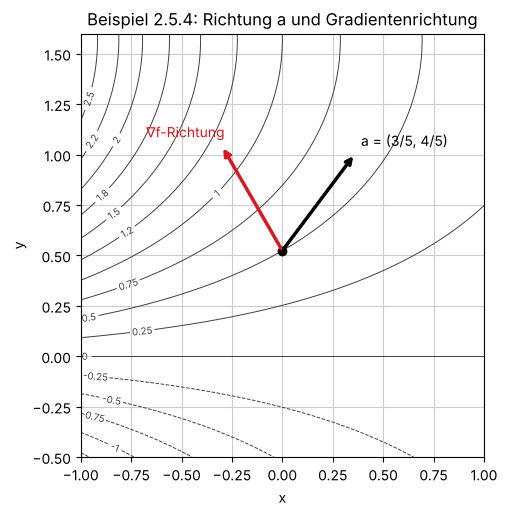

In [4]:
f254 = sp.exp(-x)*sp.sin(y)
P = {x: 0, y: sp.pi/6}
a254 = sp.Matrix([sp.Rational(3, 5), sp.Rational(4, 5)])
pruefe('||a|| - 1', a254.norm() - 1)
grad254 = sp.Matrix([f254]).jacobian([x, y]).subs(P)
rab = (grad254*a254)[0]
pruefe('Skript-Ergebnis', rab - (-sp.Rational(3, 10) + 2*sp.sqrt(3)/5))
print('Richtungsableitung ≈', float(rab), ',  maximale Steigung ||∇f|| =', sp.nsimplify(grad254.norm()))

fn = sp.lambdify((x, y), f254, 'numpy')
fig, ax = plt.subplots(figsize=(6.5, 5.5))
hoehenlinien(fn, (-1, 1), (-0.5, 1.6), ax=ax, niveaus=np.linspace(-1.5, 2.5, 17), gefuellt=False)
p = np.array([0, np.pi/6]); g = np.array(grad254, dtype=float).ravel()
ax.annotate('', p + np.array([0.6, 0.8])*0.6, p, arrowprops=dict(arrowstyle='->', lw=2.5, color='black'))
ax.annotate('', p + g/np.linalg.norm(g)*0.6, p, arrowprops=dict(arrowstyle='->', lw=2.5, color=ROT))
ax.text(*(p + np.array([0.6, 0.8])*0.65), 'a = (3/5, 4/5)'); ax.text(*(p + g/np.linalg.norm(g)*0.65 + [-0.35, 0]), '∇f-Richtung', color=ROT)
ax.plot(*p, 'ko'); ax.set(title='Beispiel 2.5.4: Richtung a und Gradientenrichtung')
plt.show()

## 5. Beispiel 2.5.5: Abhängigkeit vom Winkel

Für $f(x,y) = x^2 + 2xy$ ist $f_x = 2x + 2y$, $f_y = 2x$ und damit $\nabla f(1,1) = (4, 2)$. Für $a = (\cos\alpha, \sin\alpha)$ liefert die **Definition** (Grenzwert):
$$\frac{\partial f}{\partial a}(1,1) = \lim_{\lambda\to 0}\frac{f(1 + \lambda\cos\alpha, 1 + \lambda\sin\alpha) - 3}{\lambda} = 4\cos\alpha + 2\sin\alpha = a\cdot\nabla f(1,1).$$
Das Maximum $\sqrt{20}$ liegt bei $\tan\alpha^* = \frac12$, also genau in Richtung des Gradienten.

**Interaktiv:** Drehen Sie die Richtung $a$. Links sieht man die Richtung in der Ebene, rechts den Wert der Richtungsableitung auf der Kurve $4\cos\alpha + 2\sin\alpha$.

Probe Definition = 4cos α + 2sin α: Residuum = 0  -> ok
α* = arctan(1/2) ≈ 26.56505117707799 °,  Maximum = 2*sqrt(5)


IntSlider(value=45, continuous_update=False, description='α (Grad)', max=360, step=5)

Output()

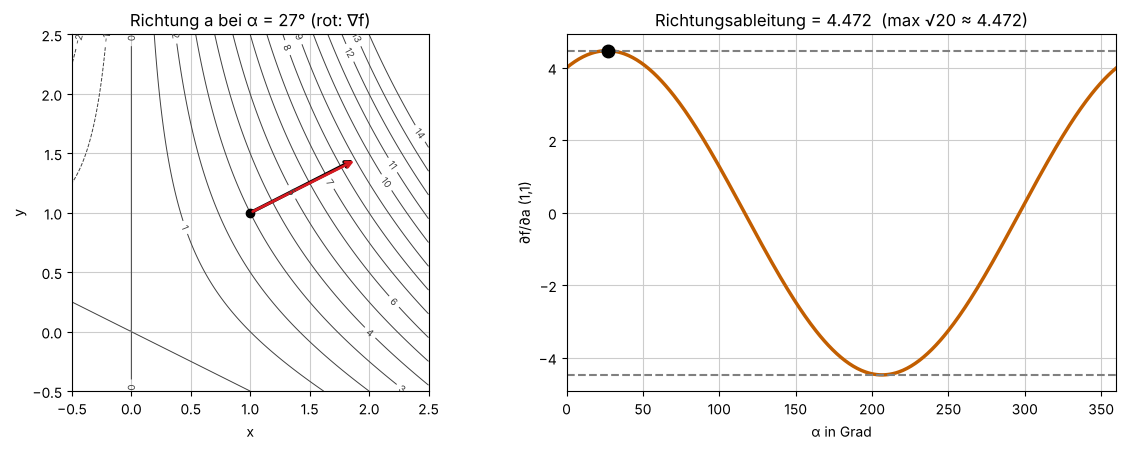

In [5]:
f255 = x**2 + 2*x*y
def_rab = sp.limit((f255.subs({x: 1 + lam*sp.cos(alpha), y: 1 + lam*sp.sin(alpha)}) - 3)/lam, lam, 0)
pruefe('Definition = 4cos α + 2sin α', def_rab - (4*sp.cos(alpha) + 2*sp.sin(alpha)))
alpha_stern = sp.atan(sp.Rational(1, 2))
print('α* = arctan(1/2) ≈', float(alpha_stern)*180/np.pi, '°,  Maximum =', sp.simplify(def_rab.subs(alpha, alpha_stern)))
fn255 = sp.lambdify((x, y), f255, 'numpy')


def zeige_richtung(winkel=45):
    al = np.radians(winkel); a_v = np.array([np.cos(al), np.sin(al)]); wert = 4*np.cos(al) + 2*np.sin(al)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
    hoehenlinien(fn255, (-0.5, 2.5), (-0.5, 2.5), ax=ax1, niveaus=np.arange(-2, 15, 1), gefuellt=False)
    ax1.annotate('', (1, 1) + a_v, (1, 1), arrowprops=dict(arrowstyle='->', lw=2.5, color='black'))
    ax1.annotate('', (1, 1) + np.array([4, 2])/np.sqrt(20), (1, 1), arrowprops=dict(arrowstyle='->', lw=2, color=ROT))
    ax1.plot(1, 1, 'ko'); ax1.set(title=f'Richtung a bei α = {winkel}° (rot: ∇f)')
    als = np.linspace(0, 2*np.pi, 400)
    ax2.plot(np.degrees(als), 4*np.cos(als) + 2*np.sin(als), color='#c25e00', linewidth=2.5)
    ax2.axhline(np.sqrt(20), color='0.5', linestyle='--'); ax2.axhline(-np.sqrt(20), color='0.5', linestyle='--')
    ax2.plot(winkel, wert, 'o', color='black', markersize=9)
    ax2.set(xlabel='α in Grad', ylabel='∂f/∂a (1,1)', xlim=(0, 360), title=f'Richtungsableitung = {wert:.3f}  (max √20 ≈ 4.472)')
    plt.tight_layout(); plt.show()


w_r = widgets.IntSlider(value=45, min=0, max=360, step=5, description='α (Grad)', continuous_update=False)
display(w_r, widgets.interactive_output(zeige_richtung, {'winkel': w_r}))

# Statische Vorschau für GitHub.
zeige_richtung(27)

## 6. Anwendung: Gradientenabstieg

Satz 2.5.3 ist die Grundlage des **Gradientenabstiegsverfahrens**, mit dem z. B. neuronale Netze trainiert werden: Um ein Minimum von $f$ zu finden, geht man schrittweise in Richtung des **steilsten Abstiegs** $-\nabla f$:
$$x_{k+1} = x_k - \eta\,\nabla f(x_k)\qquad(\eta > 0:\ \text{Lernrate}).$$
Die Schritte stehen senkrecht auf den Höhenlinien. Ausführlich behandeln das die Notebooks `gradient_descent_1d` und `gradient_descent_rosenbrock` im Ordner `numerik`.

**Interaktiv:** Für $f(x,y) = x^2 + 4y^2$ (eine langgestreckte Mulde) wird der Weg für verschiedene Lernraten gezeigt. Bei zu großer Lernrate springt das Verfahren hin und her oder divergiert (hier ab $\eta > 0{,}25$, weil die steilere Richtung den Faktor $1 - 8\eta$ hat).

Output()

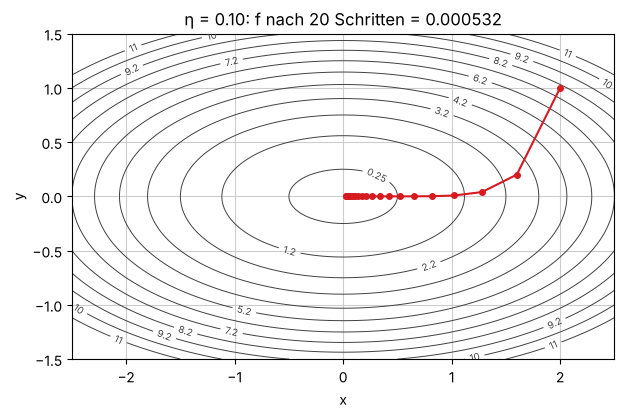

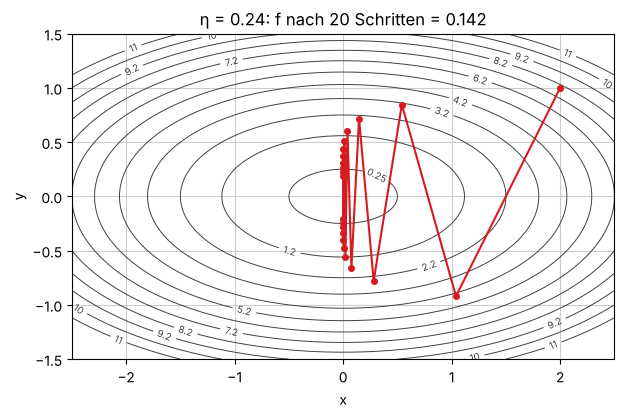

In [6]:
f_gd = lambda X, Y: X**2 + 4*Y**2
grad_gd = lambda p: np.array([2*p[0], 8*p[1]])


def zeige_abstieg(eta=0.1, schritte=20):
    p = np.array([2.0, 1.0]); weg = [p]
    for _ in range(schritte):
        p = p - eta*grad_gd(p); weg.append(p)
        if np.linalg.norm(p) > 1e3: break
    weg = np.array(weg)
    fig, ax = plt.subplots(figsize=(7, 5))
    hoehenlinien(f_gd, (-2.5, 2.5), (-1.5, 1.5), ax=ax, niveaus=np.arange(0.25, 12, 1), gefuellt=False)
    ax.plot(weg[:, 0], weg[:, 1], 'o-', color=ROT, markersize=4)
    ax.set(xlim=(-2.5, 2.5), ylim=(-1.5, 1.5), title=f'η = {eta:.2f}: f nach {len(weg) - 1} Schritten = {f_gd(*weg[-1]):.3g}')
    plt.show()


eta_r = widgets.FloatSlider(value=0.1, min=0.02, max=0.3, step=0.01, description='η', continuous_update=False)
n_r = widgets.IntSlider(value=20, min=1, max=60, description='Schritte', continuous_update=False)
display(widgets.HBox([eta_r, n_r]), widgets.interactive_output(zeige_abstieg, {'eta': eta_r, 'schritte': n_r}))

# Statische Vorschau für GitHub.
zeige_abstieg(0.1, 20)
zeige_abstieg(0.24, 20)